In [ ]:
from google.colab import files

uploaded = files.upload()

Saving heart_disease_dataset.csv to heart_disease_dataset.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset uploaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset uploaded successfully!
Dataset shape: (400, 14)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,heart_disease
0,58,1,1,134,246,0,0,155,0,0.4,1,1,2,1
1,52,0,2,112,245,0,0,143,1,0.1,0,0,3,1
2,59,0,2,126,196,0,0,162,1,1.1,1,0,1,1
3,67,1,1,165,201,0,0,180,0,0.4,2,0,2,0
4,51,1,0,146,174,1,1,133,1,0.9,1,1,2,1


In [ ]:
# Display dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check target column values
print("\nHeart disease distribution:")
print(df["heart_disease"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      400 non-null    int64  
 1   sex                      400 non-null    int64  
 2   chest_pain_type          400 non-null    int64  
 3   resting_blood_pressure   400 non-null    int64  
 4   cholesterol              400 non-null    int64  
 5   fasting_blood_sugar      400 non-null    int64  
 6   resting_ecg              400 non-null    int64  
 7   max_heart_rate           400 non-null    int64  
 8   exercise_induced_angina  400 non-null    int64  
 9   st_depression            400 non-null    float64
 10  st_slope                 400 non-null    int64  
 11  num_major_vessels        400 non-null    int64  
 12  thalassemia              400 non-null    int64  
 13  heart_disease            400 non-null    int64  
dtypes: float64(1), int64(13)
m

In [ ]:
df.describe()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,heart_disease
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,53.667500,0.662500,1.712500,123.630000,216.627500,0.140000,0.530000,146.717500,0.29250,0.753250,1.177500,0.677500,1.925000,0.555000
std,8.508403,0.473449,1.035628,16.567114,41.379941,0.347422,0.533678,21.104293,0.45548,0.772841,0.645784,0.889084,0.689611,0.497588
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,91.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,1.000000,112.000000,188.000000,0.000000,0.000000,132.000000,0.00000,0.200000,1.000000,0.000000,2.000000,0.000000
50%,54.000000,1.000000,2.000000,124.000000,216.000000,0.000000,1.000000,146.000000,0.00000,0.600000,1.000000,0.000000,2.000000,1.000000
75%,59.000000,1.000000,3.000000,135.000000,246.000000,0.000000,1.000000,161.000000,1.00000,0.900000,2.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,174.000000,336.000000,1.000000,2.000000,202.000000,1.00000,4.900000,2.000000,3.000000,3.000000,1.000000


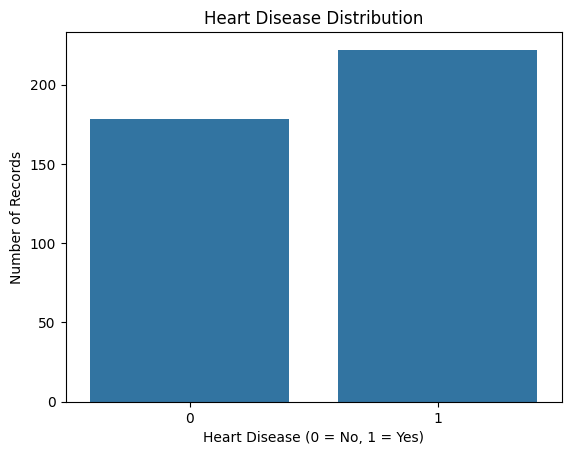

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="heart_disease")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

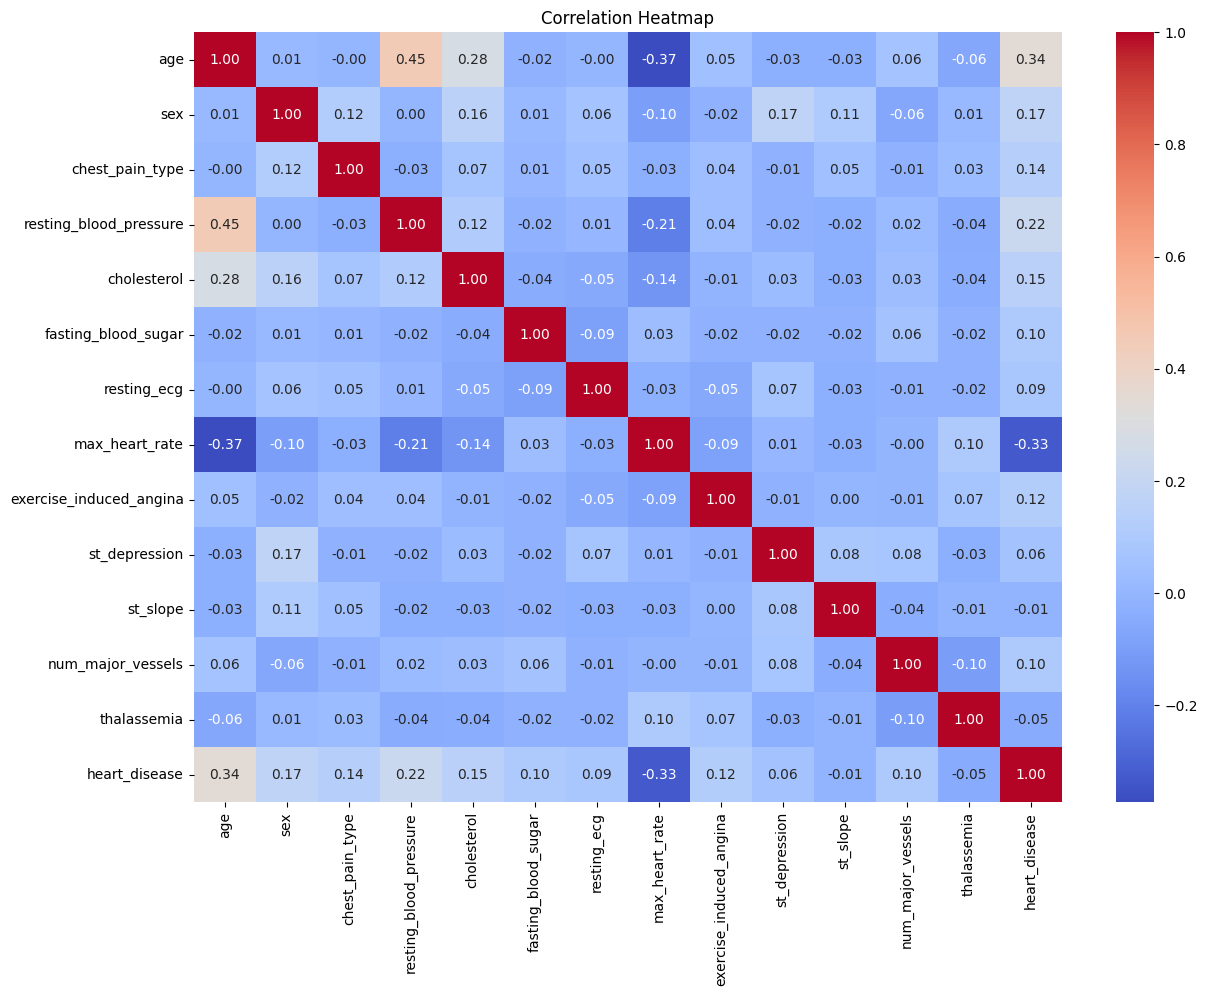

In [ ]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

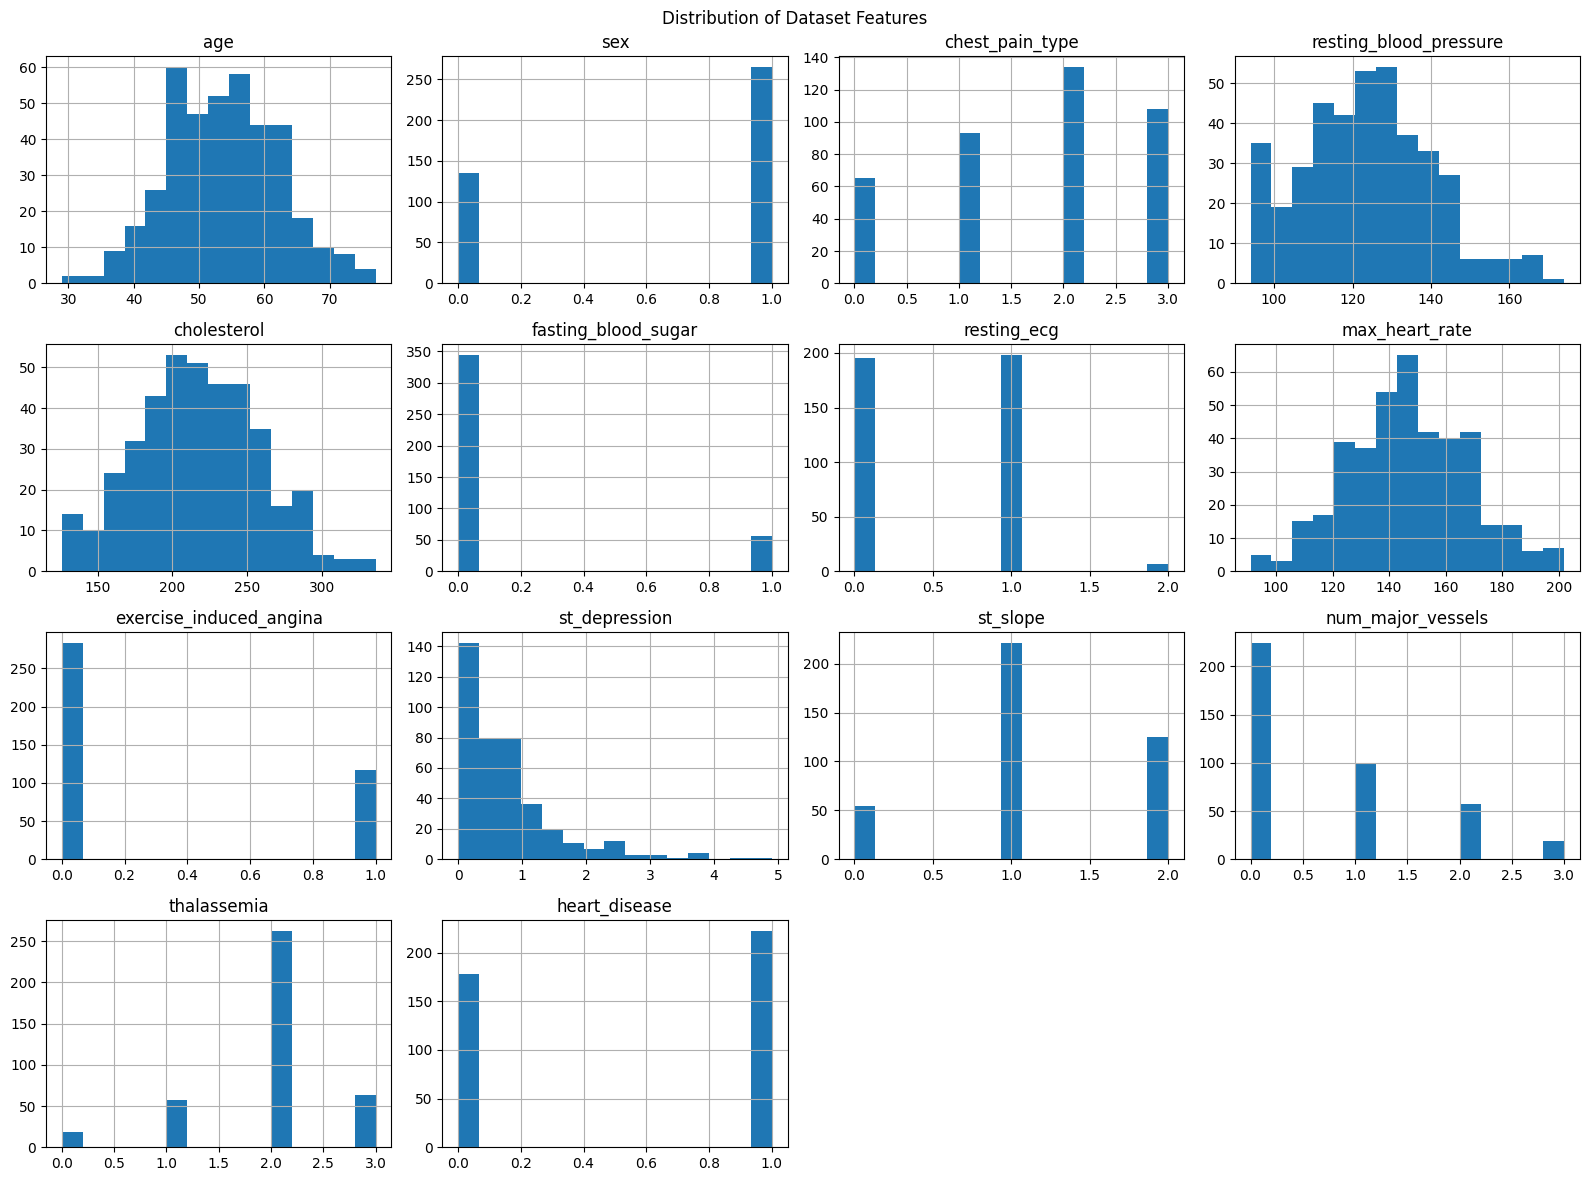

In [ ]:
df.hist(figsize=(16, 12), bins=15)
plt.suptitle("Distribution of Dataset Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("heart_disease", axis=1)
y = df["heart_disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training records: 320
Testing records: 80
Number of input features: 13


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

# Train all four models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Decision Tree trained successfully
Random Forest trained successfully
Logistic Regression trained successfully
SVM trained successfully


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

results = []
predictions = {}

for name, model in models.items():

    # Predicted classes
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Probability of class 1 for ROC-AUC
    y_prob = model.predict_proba(X_test)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "Specificity": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Specificity,ROC-AUC
0,Decision Tree,0.575,0.600,0.682,0.638,0.444,0.563
1,Random Forest,0.688,0.694,0.773,0.731,0.583,0.782
2,Logistic Regression,0.675,0.696,0.727,0.711,0.611,0.734
3,SVM,0.650,0.674,0.705,0.689,0.583,0.735


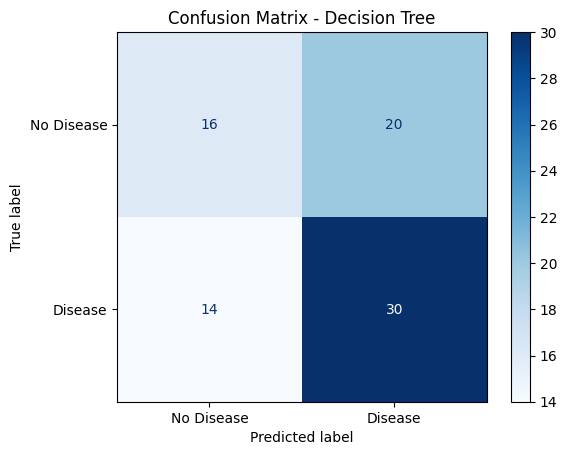

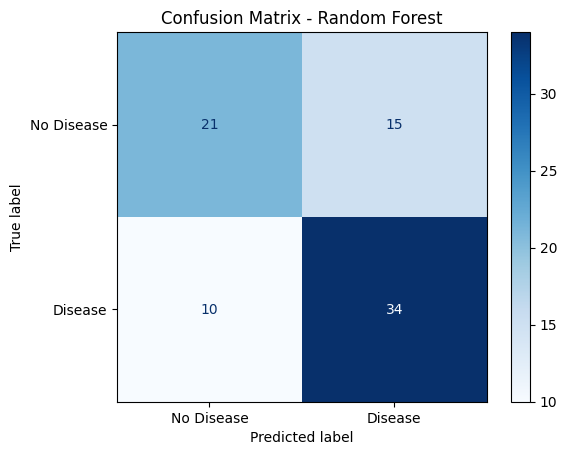

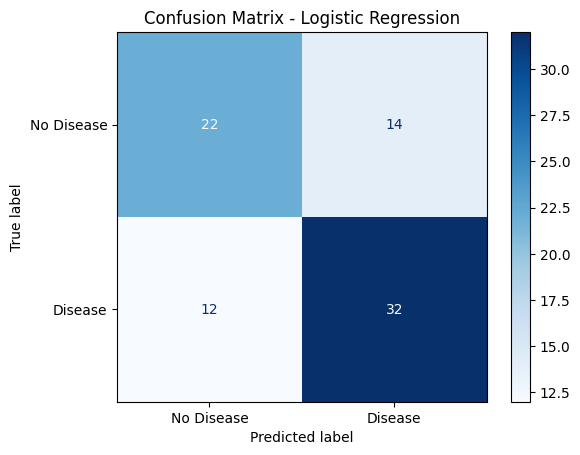

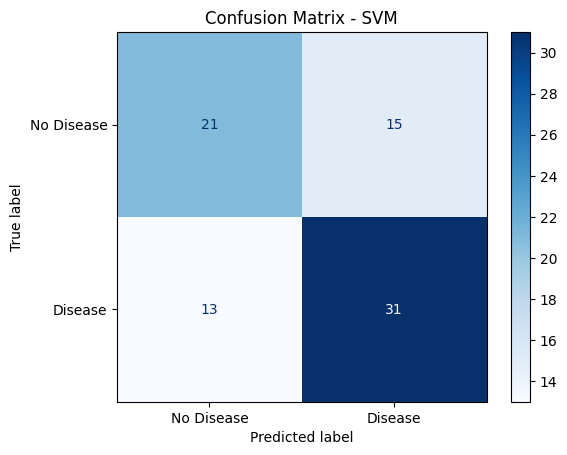

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        labels=[0, 1],
        display_labels=["No Disease", "Disease"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

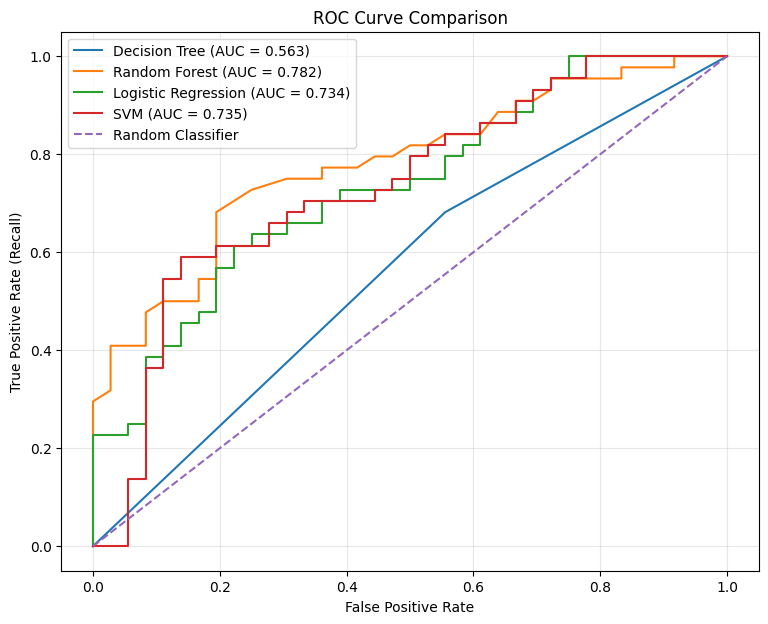

In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc(fpr, tpr):.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df)

best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Highest ROC-AUC model:", best_model_name)
print(
    "ROC-AUC:",
    round(results_df.loc[0, "ROC-AUC"], 3)
)

,Model,Accuracy,Precision,Recall,F1 Score,Specificity,ROC-AUC
0,Random Forest,0.6875,0.693878,0.772727,0.731183,0.583333,0.781566
1,SVM,0.6500,0.673913,0.704545,0.688889,0.583333,0.735480
2,Logistic Regression,0.6750,0.695652,0.727273,0.711111,0.611111,0.734217
3,Decision Tree,0.5750,0.600000,0.681818,0.638298,0.444444,0.563131


Highest ROC-AUC model: Random Forest
ROC-AUC: 0.782


,Feature,Importance
7,max_heart_rate,0.175388
0,age,0.146664
4,cholesterol,0.140299
3,resting_blood_pressure,0.131372
9,st_depression,0.104426
2,chest_pain_type,0.057524
11,num_major_vessels,0.048840
1,sex,0.044671
10,st_slope,0.037854
12,thalassemia,0.035447


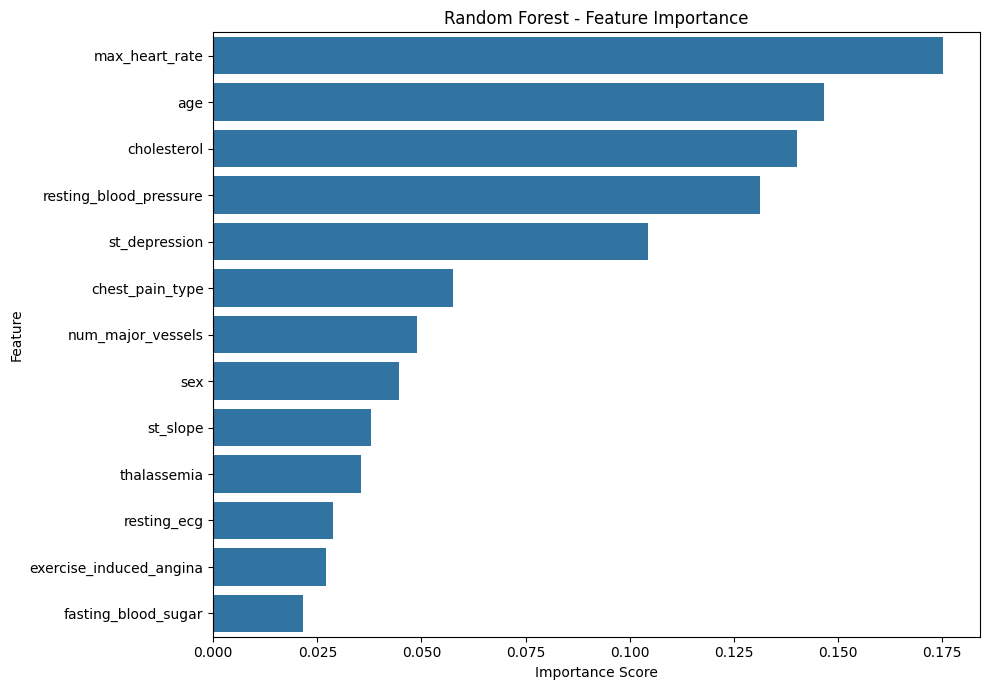

In [ ]:
rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:

# Step 1: Train and save the Random Forest model

import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier
from google.colab import files
import os

# Use the existing dataset, or upload it if needed
if "df" not in globals():
    if os.path.exists("heart_disease_dataset.csv"):
        df = pd.read_csv("heart_disease_dataset.csv")
    else:
        print("Please upload your dataset CSV file.")
        uploaded = files.upload()
        csv_files = [f for f in uploaded if f.lower().endswith(".csv")]

        if not csv_files:
            raise ValueError("No CSV file uploaded. Please upload the dataset.")

        df = pd.read_csv(csv_files[0])

# Clean column names
df.columns = df.columns.str.strip()

# Find the target column
target_candidates = ["heart_disease", "heart_desease"]
target = next(
    (c for c in df.columns if c.lower() in target_candidates),
    None
)

if target is None:
    raise ValueError(
        f"Target column not found. Available columns: {list(df.columns)}"
    )

# Prepare features and target
X = df.drop(columns=[target])
y = df[target]

# Train the final Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X, y)

# Save model and feature names together
model_bundle = {
    "model": rf_model,
    "feature_names": list(X.columns)
}

joblib.dump(model_bundle, "heart_disease_model.joblib")

print("Model trained and saved successfully!")
print("Features:", len(X.columns))
print("File: heart_disease_model.joblib")

# Download the saved model
files.download("heart_disease_model.joblib")


Model trained and saved successfully!
Features: 13
File: heart_disease_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip install fastapi uvicorn


In [ ]:

%%writefile app.py

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

# Load the saved model
bundle = joblib.load("heart_disease_model.joblib")
model = bundle["model"]
feature_names = bundle["feature_names"]

app = FastAPI(title="Heart Disease Prediction API")

class PatientData(BaseModel):
    features: list[float]

@app.get("/")
def home():
    return {"message": "Heart Disease Prediction API is running"}

@app.post("/predict")
def predict(data: PatientData):
    if len(data.features) != len(feature_names):
        return {
            "error": f"Expected {len(feature_names)} features"
        }

    patient = pd.DataFrame(
        [data.features],
        columns=feature_names
    )

    prediction = int(model.predict(patient)[0])

    return {
        "prediction": prediction,
        "result": (
            "Heart disease detected by model"
            if prediction == 1
            else "No heart disease detected by model"
        ),
        "note": "Educational prediction only; not a medical diagnosis."
    }


Writing app.py


In [ ]:

import os

print("Model file exists:", os.path.exists("heart_disease_model.joblib"))
print("API file exists:", os.path.exists("app.py"))


Model file exists: True
API file exists: True


In [ ]:

import os

assert os.path.exists("heart_disease_model.joblib"), "Model file missing!"
assert os.path.exists("app.py"), "API file missing!"

print("Both files are ready!")


Both files are ready!


In [ ]:
import subprocess
import time
import requests

server = subprocess.Popen(
    ["uvicorn", "app:app", "--host", "127.0.0.1", "--port", "8000"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

for i in range(10):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=2
        )
        print("Status:", response.status_code)
        print("Response:", response.json())
        break
    except requests.RequestException:
        time.sleep(1)
else:
    print("API did not start. Check the app.py file.")

8000/tcp:            32206
Server Status: 200
Server Response: {'message': 'Heart Disease Prediction API is running'}


In [ ]:
import subprocess
import time
import requests

# Start API on a different port
server = subprocess.Popen(
    ["python", "-m", "uvicorn", "app:app",
     "--host", "127.0.0.1", "--port", "8001"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

for i in range(10):
    try:
        response = requests.get(
            "http://127.0.0.1:8001/",
            timeout=2
        )
        print("Status:", response.status_code)
        print("Response:", response.text)
        break
    except requests.RequestException:
        time.sleep(1)
else:
    print("API failed to respond.")

Status: 200
Response: {"message":"Heart Disease Prediction API is running"}


In [ ]:
import requests

url = "http://127.0.0.1:8001/predict"

data = {
    "features": [50, 1, 2, 130, 230, 0, 1, 150, 0, 1.0, 1, 0, 2]
}

response = requests.post(url, json=data, timeout=10)

print("Status:", response.status_code)
print("Prediction:", response.text)

Status: 200
Prediction: {"prediction":0,"result":"No heart disease detected by model","note":"Educational prediction only; not a medical diagnosis."}


In [ ]:
from IPython.display import display, HTML

display(HTML("""
<a href="http://127.0.0.1:8001/docs" target="_blank">
Open FastAPI Documentation
</a>
"""))

In [ ]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8001)"))

https://8001-m-s-kkb-usw1c2-4qkvamzc18cc-c.us-west1-2.prod.colab.dev


In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8001)")
print(url.rstrip("/") + "/docs")


https://8001-m-s-kkb-usw1c2-4qkvamzc18cc-c.us-west1-2.prod.colab.dev/docs


In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nProject files:")

for file in os.listdir():
    print(file)

Current folder: /content

Project files:
.config
.ipynb_checkpoints
app.py
heart_disease_dataset.csv
heart_disease_model.joblib
__pycache__
sample_data


In [ ]:
%%writefile Dockerfile
FROM python:3.11-slim

WORKDIR /app

COPY app.py .
COPY heart_disease_model.joblib .

RUN pip install --no-cache-dir fastapi uvicorn pandas scikit-learn joblib

EXPOSE 8000

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

Writing Dockerfile


In [ ]:
!cat Dockerfile

FROM python:3.11-slim

WORKDIR /app

COPY app.py .
COPY heart_disease_model.joblib .

RUN pip install --no-cache-dir fastapi uvicorn pandas scikit-learn joblib

EXPOSE 8000

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]


In [ ]:
!docker --version

/bin/bash: line 1: docker: command not found


In [22]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn==1.6.1
fastapi
uvicorn
joblib

Writing requirements.txt


In [23]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>